# Dataset Statistics: Identification Drift over Time

Characterises how the number of identified precursors and proteins changes as a function of time at two scales:

1. **Inter-day variability** — identification counts per condition, broken down by acquisition day per lab. Reveals whether instrument performance is consistent between measurement sessions or degrades/improves over the course of the study.
2. **Long-term stability** — normalised identification counts plotted against days elapsed since a lab's first acquisition. Summarised as median ± IQR across all cells of each condition, enabling direct cross-lab comparison of multi-day performance trends.
3. **Intra-day drift** — within a single acquisition day, how identification depth changes with injection order. Time within each day is normalised to [0, 1] and a linear regression is fitted per lab × condition. Statistically significant negative slopes indicate that later-injected cells yield fewer identifications — a classic sign of column overloading, carry-over, or electrospray instability.

Throughout this notebook, samples flagged as `completeness_outlier` (failed injections) are excluded to prevent near-empty runs from distorting drift estimates.

**Inputs** (`Data/AnnData/`)

| File | Description |
|---|---|
| `adata_precursor.h5ad` | Precursor-level quantification (samples × precursors) |
| `adata_protein.h5ad` | Protein-level quantification (samples × protein groups) |

**Outputs** (`Figures/Figure_4/Drift/`)

All figures are saved as png, svg, and pdf.

| Subfolder | File pattern | Description |
|---|---|---|
| `Across_days/` | `{lab}_precursor_DriftByDay` | Per-lab precursor counts, split by acquisition day |
| `Across_days/` | `{lab}_protein_DriftByDay` | Per-lab protein counts, split by acquisition day |
| `Within_day/` | `Overview_precursor_DriftWithinDay` | Long-term precursor stability, all labs |
| `Within_day/` | `Overview_protein_DriftWithinDay` | Long-term protein stability, all labs |
| `Correlation/` | `{lab}_drift_precursor` | Per-lab intra-day precursor drift regression |
| `Correlation/` | `{lab}_drift_protein` | Per-lab intra-day protein drift regression |
| `Correlation/` | `drift_significance` | Heatmap of BH-corrected drift p-values |

---

## Imports

In [1]:
import os
from tqdm import tqdm
import numpy as np
import pandas as pd
from pathlib import Path
import anndata

from statsmodels.stats.multitest import multipletests

from SCI_py.constants.maps import LABS
from SCI_py.metrics.drift import compute_drift, fit_drift_stats, compute_rt_drift_correlations, compute_time_norm
from SCI_py.plot.drift import plot_drift_significance, plot_drift, plot_features_by_day, plot_feature_stability, plot_rt_drift_precursor, plot_rt_drift_correlations

from SCI_py.metrics.rt_stability import compute_rt_proportions
from SCI_py.plot.rt_stability import plot_rt_stability

tqdm.pandas()

## 0. Path Configuration

Output directories are resolved relative to the notebook location and created automatically if absent. Both can be overridden via environment variables, which is useful for running the notebook in a CI pipeline or on a different machine without editing the notebook.

| Variable | Default | Environment override |
|---|---|---|
| `ROOT_OUT` | `../../Data` | `SCI_DATA_DIR` |
| `FIGURES_OUT` | `../../Figures` | `SCI_FIGURES_DIR` |

AnnData objects are expected under `ROOT_OUT/AnnData/`, produced by `02_Results_to_AnnData.ipynb`.

In [2]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

FIGURES_OUT = NOTEBOOK_DIR / "../../Figures"
FIGURES_OUT = FIGURES_OUT.resolve()
FIGURES_OUT.mkdir(parents=True, exist_ok=True)

# Overwrite with environment variable
FIGURES_OUT = Path(os.environ.get("SCI_FIGURES_DIR", FIGURES_OUT))
print(f"Figures directory: {FIGURES_OUT}")

ANNDATA_IN = os.path.join(
    ROOT_OUT,
    'AnnData',
    'out'
)

Output directory: /home/sam/SCI/SCI/Data
Figures directory: /home/sam/SCI/SCI/Figures


In [3]:
SHOW_FIGURES = False

## 1. Load Data

Load the pre-processed AnnData objects for precursor-level and protein-level quantification. Both are expected to carry `completeness_outlier` in `obs` (written by `02_QC_Metrics.ipynb`), which is used throughout this notebook to exclude failed injections before computing drift statistics.

Two condition lists are defined:

- `conditions_cell_QC` — all four biological/QC conditions (K562, HEK293T, HeLa QC, site-specific QC). Used for the per-day and stability plots where QC injections provide a stable reference.
- `condition_cell` — the two primary cell-line conditions (K562, HEK293T) only. Used for better visualizations of certain figures.

In [4]:
adata_precursor = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_precursor.h5ad')
)
adata_protein = anndata.io.read_h5ad(
    os.path.join(ANNDATA_IN, 'adata_protein.h5ad')
)

conditions_cell_QC = ['K562', 'HEK293T', 'Site specific QC', 'QC - Hela']
condition_cell = ['K562', 'HEK293T']

## 2. Inter-day Variability

Visualises how identification depth varies between different acquisition days for each lab. For each lab, `plot_features_by_day` produces a grouped boxplot where:

- **x-axis** — biological/QC condition (K562, HEK293T, HeLa QC, site-specific QC).
- **Colour (hue)** — individual acquisition date, ordered chronologically and coloured on a blue gradient from lightest (earliest day) to darkest (latest day). This makes it immediately apparent whether later days systematically under- or over-perform relative to earlier sessions.
- **y-axis** — identification count normalised to the per-condition maximum (`normalize=True`), expressed as a percentage. Normalisation removes the absolute-count difference between conditions and focuses attention on day-to-day consistency within each condition.

One figure is produced per lab at both precursor and protein level, saved under `Across_days/`.

In [5]:
conditions = ['K562', 'HEK293T', 'Site specific QC', 'QC - Hela']

# Single lab, by day
for plate_idx in LABS:
    plot_features_by_day(
        # Filter out failed samples
        adata=adata_precursor[
            ~adata_precursor.obs['completeness_outlier']
        ],
        count_col='n_precursors',
        lab=plate_idx,
        conditions=conditions_cell_QC,
        normalize=True,
        save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Across_days'),
        filename=f'{plate_idx}_precursor_DriftByDay',
        show=SHOW_FIGURES
    )
    plot_features_by_day(
        # Filter out failed samples
        adata=adata_protein[
            ~adata_protein.obs['completeness_outlier']
        ],
        count_col='n_proteins',
        lab=plate_idx,
        conditions=conditions_cell_QC,
        normalize=True,
        save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Across_days'),
        filename=f'{plate_idx}_protein_DriftByDay',
        show=SHOW_FIGURES
    )

## 3. Long-term Identification Stability

Summarises identification depth over the full data-collection period for all plates simultaneously. `plot_feature_stability` computes, for each plate and each condition:

1. The per-day maximum identification count (the reference for normalisation).
2. For every cell, its count as a percentage of that maximum — `{count_col}_pct`.
3. The daily median and interquartile range across all cells, plotted as a line ± shaded band against **days since first acquisition** (day 0 = the plate's first measurement session).

Each lab is drawn in its designated colour (`LAB_COLORS`). Labs that acquired all data in a single session appear as a point rather than a trajectory. A flat, overlapping bundle of lines across labs indicates stable, comparable performance throughout the study; diverging or declining trajectories flag plates where instrument performance drifted significantly over time.

One figure is produced for each quantification level (precursor and protein), with one panel per condition, saved under `Within_day/`.

In [6]:
# All labs, stability over time
plot_feature_stability(
    adata=adata_precursor[
        ~adata_precursor.obs['completeness_outlier']
    ],
    count_col='n_precursors',
    conditions=conditions_cell_QC,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Within_day'),
    filename='Overview_precursor_DriftWithinDay',
    show=False
)

# Using proteins instead
plot_feature_stability(
    adata=adata_protein[
        ~adata_protein.obs['completeness_outlier']
    ],
    count_col='n_proteins',
    conditions=conditions_cell_QC,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Within_day'),
    filename='Overview_protein_DriftWithinDay',
    show=False
)

## 4. Intra-day Drift

Measures whether identification depth decreases (or increases) systematically within a single acquisition day as a function of injection order. This is the most direct proxy for LC column conditioning, carry-over accumulation, or electrospray instability.

**Normalisation** — `compute_drift` normalises the clock time of each injection to [0, 1] within its calendar day (`time_norm = 0` = first injection of the day, `time_norm = 1` = last injection). Identification counts are similarly normalised to the per-condition, per-day maximum, yielding `{count_col}_pct`.

**Regression** — `fit_drift_stats` fits an ordinary least-squares linear regression of `{count_col}_pct ~ time_norm` per lab × condition. The slope (in % per normalised time unit) quantifies the magnitude of drift; the p-value tests whether the trend is distinguishable from noise.

**Multiple-testing correction** — raw p-values are corrected across all lab × condition combinations using the Benjamini–Hochberg (BH) procedure at α = 0.05. `plot_drift_significance` displays the corrected p-values as a colour-coded heatmap, with annotation stars for three significance tiers (*, **, ***).

`KI_Astral_2` is skipped in the per-lab scatter plots due to insufficient data for that instrument.

One scatter + regression figure is produced per lab at both precursor and protein level, plus a single combined significance heatmap, all saved under `Correlation/`.

Note that we look at the drift within a day here, and not the entirety of the injection order as these are run over several days. The reason why here we normalize per day is because we want to only look at the intra-day drift here.

In [7]:
# Compute once per adata
drift_precursor = compute_drift(
    adata=adata_precursor[
        ~adata_precursor.obs['completeness_outlier']
    ],
    conditions=conditions_cell_QC,
    count_col='n_precursors'
)
drift_protein = compute_drift(
    adata=adata_protein[
        ~adata_protein.obs['completeness_outlier']
    ],
    conditions=conditions_cell_QC,
    count_col='n_proteins'
)

# Plot per lab
for lab in LABS:
    # Missing data for this plate
    if lab == 'KI_Astral_2':
        continue
    
    plot_drift(
        drift_df=drift_precursor,
        lab=lab,
        count_col='n_precursors',
        conditions=conditions_cell_QC,
        save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Correlation'),
        filename=f'{lab}_drift_precursor',
        show=SHOW_FIGURES
    )
    plot_drift(
        drift_df=drift_protein,
        lab=lab,
        count_col='n_proteins',
        conditions=conditions_cell_QC,
        save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Correlation'),
        filename=f'{lab}_drift_protein',
        show=SHOW_FIGURES
    )

In [8]:
# Fit stats and correct
stats_prec = fit_drift_stats(
    drift_df=drift_precursor,
    count_col='n_precursors'
).assign(adata_type='precursor')

stats_prot = fit_drift_stats(
    drift_df=drift_protein,
    count_col='n_proteins'
).assign(adata_type='protein')

for df in (stats_prec, stats_prot):
    _, df['p_value_bh'], _, _ = multipletests(df['p_value'], method='fdr_bh')

stats_all = pd.concat([stats_prec, stats_prot])

plot_drift_significance(
    stats_df=stats_all,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'Correlation'),
    filename='drift_significance',
    show=False
)

## 5. Retention time displacement of precursors

As an interesting extra aspect, we will look at the difference in detected retention time of the precursors over the entirety of the injection range. For each precursor, with at least n identifications across the condition, the spearman correlation is calculated between the retention time and the injection order. Higher correlations mean that the retention times become longer for samples acquired later. In other words, the retention decreases in the column. The reverse might also be the case, that for some precursors the retention increases.

To show why we expect this, the gradient plots are now colored by injection order. A trend is distinguishable. This trend is similar for the other plates to different degrees.

In [9]:
rt_props = []

conditions = ['HEK293T', 'K562']

for lab_name in LABS:
    rt_props_lab = compute_rt_proportions(
        adata=adata_precursor[
            (adata_precursor.obs['plate_idx']==lab_name) &
            (~adata_precursor.obs['completeness_outlier']) &
            (adata_precursor.obs['source name'].isin(conditions))
        ],
        rt_layer='EG.ApexRT_norm',
        bins=30,
    )
    rt_props_lab = rt_props_lab.merge(adata_precursor.obs.reset_index(), how='left')
    rt_props.append(rt_props_lab)
rt_props = pd.concat(rt_props, ignore_index=True)

for lab_name in LABS:
    plot_rt_stability(
        rt_props  = rt_props.loc[
            (rt_props['plate_idx']==lab_name) &
            (rt_props['source name'].isin(['K562', 'HEK293T'])),
            :
        ],
        color_by  = 'injection_order',
        cmap      = 'plasma',
        show_mean = False,
        title     = 'Single cell',
        save_dir  = os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'RT', 'Gradient_plots'),
        filename  = f"RT_stability_Norm_{lab_name}.png",
        show      = SHOW_FIGURES,
    )

To do this analysis, we can leverage the EG.ApexRT layer within the adata_precursor objects.

In [10]:
correlation_dict_unnormalized = {}
correlation_dict_normalized = {}

for lab_name in LABS:
    if lab_name == 'Astral_6':
        continue
    correlations_unnormalized = compute_rt_drift_correlations(
        adata = adata_precursor[
            (adata_precursor.obs['plate_idx'] == lab_name) &
            (~adata_precursor.obs['completeness_outlier']) &
            (adata_precursor.obs['source name'].isin(['HEK293T', 'K562']))
        ],
        correlation_col='injection_order',
        rt_layer='EG.ApexRT',
        min_n=100
    )
    correlations_normalized = compute_rt_drift_correlations(
        adata = adata_precursor[
            (adata_precursor.obs['plate_idx'] == lab_name) &
            (~adata_precursor.obs['completeness_outlier']) &
            (adata_precursor.obs['source name'].isin(['HEK293T', 'K562']))
        ],
        rt_layer='EG.ApexRT_norm',
        correlation_col='injection_order',
        min_n=100
    )

    correlation_dict_unnormalized[lab_name] = correlations_unnormalized
    correlation_dict_normalized[lab_name] = correlations_normalized

Calculating correlations...: 72061it [00:02, 33835.20it/s]
Calculating correlations...: 72061it [00:02, 33000.65it/s]
Calculating correlations...: 72061it [00:02, 27197.90it/s]
Calculating correlations...: 72061it [00:02, 28304.31it/s]
Calculating correlations...: 72061it [00:01, 55183.76it/s]
Calculating correlations...: 72061it [00:01, 54893.53it/s]
Calculating correlations...: 72061it [00:01, 50960.98it/s]
Calculating correlations...: 72061it [00:01, 51153.14it/s]
Calculating correlations...: 72061it [00:01, 47902.66it/s]
Calculating correlations...: 72061it [00:01, 41628.92it/s]
Calculating correlations...: 72061it [00:02, 34106.24it/s]
Calculating correlations...: 72061it [00:02, 33343.75it/s]
Calculating correlations...: 72061it [00:02, 27595.51it/s]
Calculating correlations...: 72061it [00:02, 27657.06it/s]
Calculating correlations...: 72061it [00:01, 37848.81it/s]
Calculating correlations...: 72061it [00:01, 37371.50it/s]


In [11]:
plot_rt_drift_correlations(
    correlation_dict=correlation_dict_unnormalized,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'RT', 'Correlation'),
    filename='unnormalized_rt_injection_order_correlation',
    show=False
)
plot_rt_drift_correlations(
    correlation_dict=correlation_dict_normalized,
    save_dir=os.path.join(FIGURES_OUT, 'Figure_4', 'Drift', 'RT', 'Correlation'),
    filename='normalized_rt_injection_order_correlation',
    show=False
)

A summary of spearman correlations between the normalized retention time and injection order for all precursors identified in at least 100 single-cell samples are saved below.

In [12]:
correlation_dict_normalized['timsTOF_1'].head()

,precursor,n_identified,spearman_r,spearman_p,rt_min,rt_max,rt_range
0,EM[UNIMOD:35]VLEIIR/2,114,0.492299,2.648026e-08,0.728624,0.836736,0.108112
1,M[UNIMOD:35]VFTSSADGGSYIC[UNIMOD:4]TGTLLNNGNSPK/3,167,0.476994,7.180747e-11,0.665727,0.880436,0.214710
2,LIEIENFK/2,178,0.308722,2.756190e-05,0.699600,0.820045,0.120446
3,KGGKEFVEAVLELR/3,131,0.197731,2.358349e-02,0.859993,0.933296,0.073303
4,AEIIHHLADLLTDQR/3,106,0.154213,1.144844e-01,0.894468,0.959228,0.064761


In [13]:
correlation_dict_normalized['timsTOF_1'].tail()

,precursor,n_identified,spearman_r,spearman_p,rt_min,rt_max,rt_range
8957,DGEEAGAYDGPR/2,102,-0.909200,7.728208e-40,0.085703,0.197375,0.111672
8958,[UNIMOD:1]AAM[UNIMOD:35]AVGGAGGSR/2,174,-0.910075,1.066719e-67,0.112095,0.241806,0.129711
8959,VVQVSAGDSHTAALTDDGR/3,141,-0.910317,4.168069e-55,0.194726,0.337174,0.142448
8960,LYTTM[UNIMOD:35]PVAK/2,132,-0.910693,9.313768e-52,0.162991,0.304289,0.141297
8961,YADVIVHR/2,110,-0.913748,4.741830e-44,0.179326,0.331898,0.152572


In [14]:
correlation_dict_normalized['Astral_3'].head()

,precursor,n_identified,spearman_r,spearman_p,rt_min,rt_max,rt_range
0,SYSEDDIHR/2,102,0.422124,0.000010,0.055751,0.177462,0.121711
1,AFHNEAQVNPER/3,108,0.357484,0.000146,0.068512,0.264215,0.195703
2,HVVQSISTQQEK/3,115,0.354052,0.000104,0.058934,0.182183,0.123250
3,ESLSEEEAQK/2,117,0.348964,0.000115,0.063336,0.186932,0.123596
4,KEVVEEAENGR/3,110,0.341334,0.000263,0.047111,0.159351,0.112239


Some case examples can be investigated with the following function

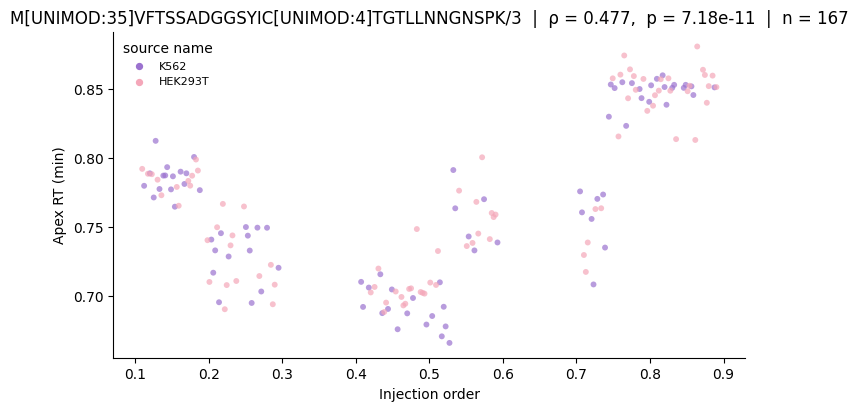

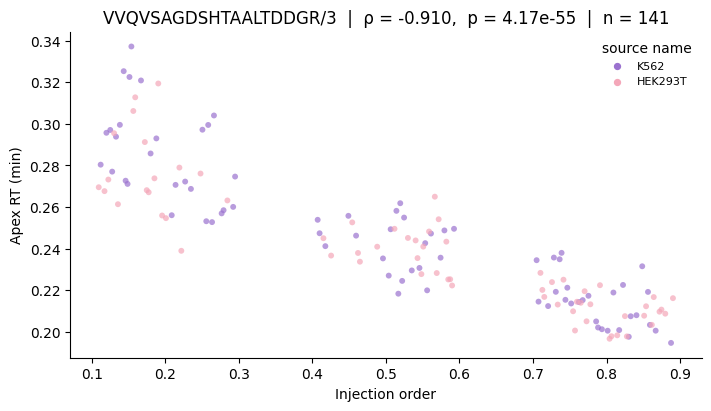

In [15]:
plot_rt_drift_precursor(
    adata = adata_precursor[
        (adata_precursor.obs['plate_idx'] == 'timsTOF_1') &
        (~adata_precursor.obs['completeness_outlier']) &
        (adata_precursor.obs['source name'].isin(conditions))
    ],
    rt_layer='EG.ApexRT_norm',
    correlation_col='injection_order',
    precursor='M[UNIMOD:35]VFTSSADGGSYIC[UNIMOD:4]TGTLLNNGNSPK/3',
)

plot_rt_drift_precursor(
    adata = adata_precursor[
        (adata_precursor.obs['plate_idx'] == 'timsTOF_1') &
        (~adata_precursor.obs['completeness_outlier']) &
        (adata_precursor.obs['source name'].isin(conditions))
    ],
    rt_layer='EG.ApexRT_norm',
    correlation_col='injection_order',
    precursor='VVQVSAGDSHTAALTDDGR/3',
)

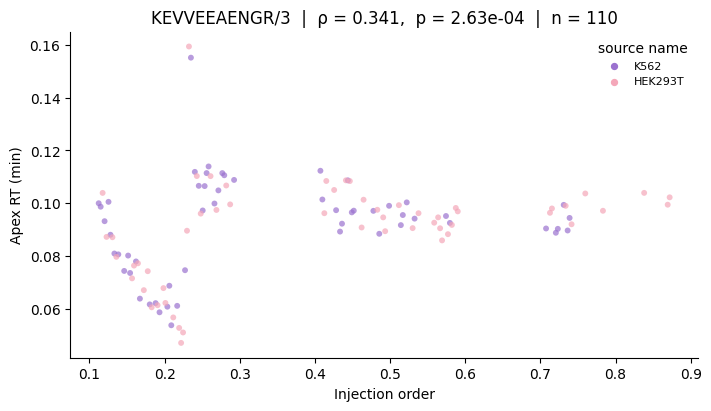

In [16]:
plot_rt_drift_precursor(
    adata = adata_precursor[
        (adata_precursor.obs['plate_idx'] == 'Astral_3') &
        (~adata_precursor.obs['completeness_outlier']) &
        (adata_precursor.obs['source name'].isin(conditions))
    ],
    rt_layer='EG.ApexRT_norm',
    correlation_col='injection_order',
    precursor='KEVVEEAENGR/3',
)

## 6. Save

In [17]:
ANNDATA_OUT = os.path.join(
    ROOT_OUT,
    'AnnData',
    'out'
)

# adata_precursor.write_h5ad(
#     os.path.join(ANNDATA_OUT, 'adata_precursor.h5ad'),
#     convert_strings_to_categoricals=False
# )
# adata_protein.write_h5ad(
#     os.path.join(ANNDATA_OUT, 'adata_protein.h5ad'),
#     convert_strings_to_categoricals=False
# )